# Lifecycle State Clustering

Group customer-months into lifecycle states (#40). Sections 1–2 build the shared feature matrix `Z`; each clustering method then has its own section.

`is_churn` is not used to build the clusters, only to check them afterwards.

## 1. Load data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import HDBSCAN
from sklearn.preprocessing import StandardScaler

base = pd.read_parquet('../data/features_and_label.parquet')        # notebook 03
drift = pd.read_parquet('../data/drift_features_monthly.parquet')   # notebook 08
df = base.merge(drift, on=['Customer ID', 'CustomerMonth'])
print(df.shape)

(75255, 47)


## 2. Features

Activity in the last 3 months, change versus the 3 months before, and days since the previous purchase. Log scaling stops big spenders from dominating, and standardizing makes each feature count equally.

In [2]:
X = pd.DataFrame({
    'log_freq_recent': np.log1p(df['freq_recent']),
    'log_rev_recent': np.log1p(df['rev_recent']),
    'log_freq_ratio': np.log(df['freq_ratio']),
    'rev_log_ratio': df['rev_log_ratio'],
    'log_days_since': np.log1p(df['days_since_last_purchase'].fillna(0)),  # missing in a customer's first month
})
Z = StandardScaler().fit_transform(X)

## 3. HDBSCAN

`min_cluster_size=200` gave a handful of clusters without one swallowing most of the data (100 gave 14 clusters, 400 put half the rows in one). Rows that fit no cluster get `-1` (noise).

In [3]:
df['cluster'] = HDBSCAN(min_cluster_size=200, copy=True).fit_predict(Z)

profile = df.groupby('cluster').agg(
    rows=('is_churn', 'size'),
    churn_rate=('is_churn', 'mean'),
    invoices_3m=('freq_recent', 'median'),
    revenue_3m=('rev_recent', 'median'),
    rev_log_ratio=('rev_log_ratio', 'median'),
    days_since_last=('days_since_last_purchase', 'median'),
    first_month_share=('is_first_month', 'mean'),
    new_in_recent_share=('is_new_in_recent', 'mean'),
)
profile.round(2)

,rows,churn_rate,invoices_3m,revenue_3m,rev_log_ratio,days_since_last,first_month_share,new_in_recent_share
cluster,,,,,,,,
-1,8018,0.20,3.0,1044.08,0.09,11.0,0.01,0.07
0,18482,0.83,0.0,0.00,0.00,277.0,0.00,0.00
1,11594,0.71,0.0,0.00,-5.54,135.0,0.00,0.00
2,2629,0.61,0.0,0.00,-6.22,118.0,0.00,0.00
3,796,0.55,0.0,0.00,-6.60,113.0,0.00,0.00
4,218,0.44,0.0,0.00,-7.12,106.5,0.00,0.00
5,3858,0.45,2.0,552.62,6.32,24.0,0.14,0.71
6,1763,0.31,3.0,932.62,6.84,17.0,0.09,0.72
7,15085,0.62,1.0,273.98,5.62,42.0,0.29,0.71


Each cluster is named from its profile. The rules are checked in order, so names still hold if cluster numbers change.

In [4]:
def name_state(p):
    if p.name == -1:
        return 'Unclustered (noise)'
    if p['first_month_share'] > 0.5 and p['invoices_3m'] <= 1:
        return 'New: one purchase'
    if p['invoices_3m'] == 0:
        # No purchases in the last 3 months
        if p['rev_log_ratio'] < -0.3:
            return 'Went quiet'   # bought in the 3 months before, then stopped
        return 'Inactive'         # no purchases in the last 6 months
    if p['new_in_recent_share'] > 0.5:
        return 'New: growing'
    if p['rev_log_ratio'] < -0.3:
        return 'Declining'
    return 'Active'

df['lifecycle_state'] = df['cluster'].map(profile.apply(name_state, axis=1))

states = df.groupby('lifecycle_state')['is_churn'].agg(rows='size', churn_rate='mean').sort_values('churn_rate')
states.round(3)

,rows,churn_rate
lifecycle_state,,
Unclustered (noise),8018,0.202
Declining,2933,0.308
Active,9879,0.367
New: growing,20706,0.565
Went quiet,15237,0.678
Inactive,18482,0.832


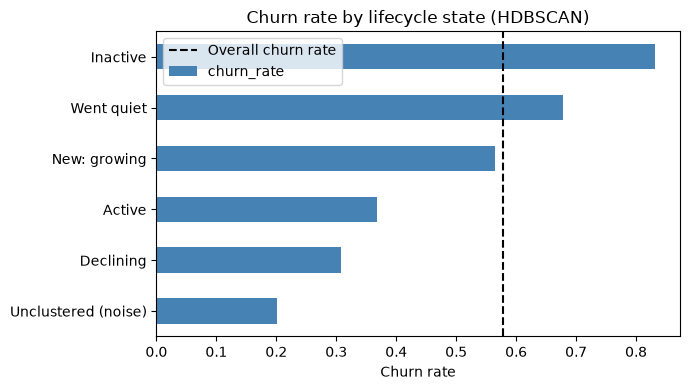

In [5]:
states['churn_rate'].plot.barh(color='steelblue', figsize=(7, 4))
plt.axvline(df['is_churn'].mean(), color='black', linestyle='--', label='Overall churn rate')
plt.xlabel('Churn rate')
plt.ylabel('')
plt.title('Churn rate by lifecycle state (HDBSCAN)')
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
df[['Customer ID', 'CustomerMonth', 'cluster', 'lifecycle_state']].to_parquet('../data/lifecycle_states_hdbscan.parquet', index=False)

## 4. K-Means / Gaussian Mixture

To be added. Reuse `Z` from section 2 so the methods are compared on the same features.

## Notes

- HDBSCAN is fit on all months. Before using `lifecycle_state` as a model feature (#41), fit on training months only.
- Rows include months with no purchases, so inactive customers get their own states (Inactive, Went quiet).